In [1]:
# Ensemble Learning with MNIST Handwritten Digits
# Import base libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

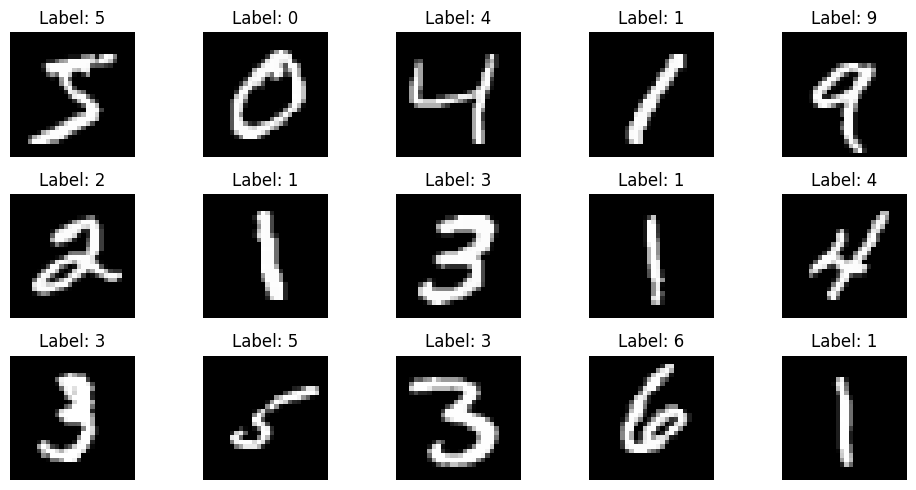

In [2]:
# Load MNIST dataset
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X, y = mnist.data, mnist.target
# Convert to numpy arrays and proper types
X = X.astype('float32') / 255.0  # Normalize pixel values to [0,1]
y = y.astype('int8')
# Split into train/test (MNIST comes pre-split)
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]
# Visualize sample digits
plt.figure(figsize=(10,5))
for i in range(15):
    plt.subplot(3,5,i+1)
    plt.imshow(X_train[i].reshape(28,28), cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
# Initialize models
dt = DecisionTreeClassifier(max_depth=10)
lr = LogisticRegression(max_iter=1000, solver='lbfgs')
svm = SVC(kernel='rbf', gamma='scale', probability=True)
# Train and evaluate
models = {'Decision Tree': dt, 'Logistic Regression': lr, 'SVM': svm}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {acc:.4f}")

Decision Tree Accuracy: 0.8671
Logistic Regression Accuracy: 0.9263
SVM Accuracy: 0.9792


In [5]:
#Bagging with Random forest:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    max_features='sqrt',
    random_state=42
)
rf.fit(X_train, y_train)
# Evaluation
y_pred_rf = rf.predict(X_test)
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9651
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.95      0.96      0.96      1032
           3       0.96      0.96      0.96      1010
           4       0.97      0.96      0.97       982
           5       0.97      0.96      0.97       892
           6       0.97      0.97      0.97       958
           7       0.97      0.95      0.96      1028
           8       0.96      0.95      0.95       974
           9       0.94      0.95      0.94      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.96      0.96     10000
weighted avg       0.97      0.97      0.97     10000



In [8]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# 3. Create a Bagging Classifier with Decision Trees as base learners
bagging_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=50,       # number of base learners
    max_samples=0.8,       # each tree trained on 80% of data
    bootstrap=True,        # sampling with replacement
    n_jobs=-1,             # parallelize
    random_state=42
)
# 4. Train the model
bagging_clf.fit(X_train, y_train)
# 5. Predictions
y_pred = bagging_clf.predict(X_test)
# 6. Accuracy
print("Bagging Classifier Accuracy on MNIST Digits:", accuracy_score(y_test, y_pred))

Bagging Classifier Accuracy on MNIST Digits: 0.9558


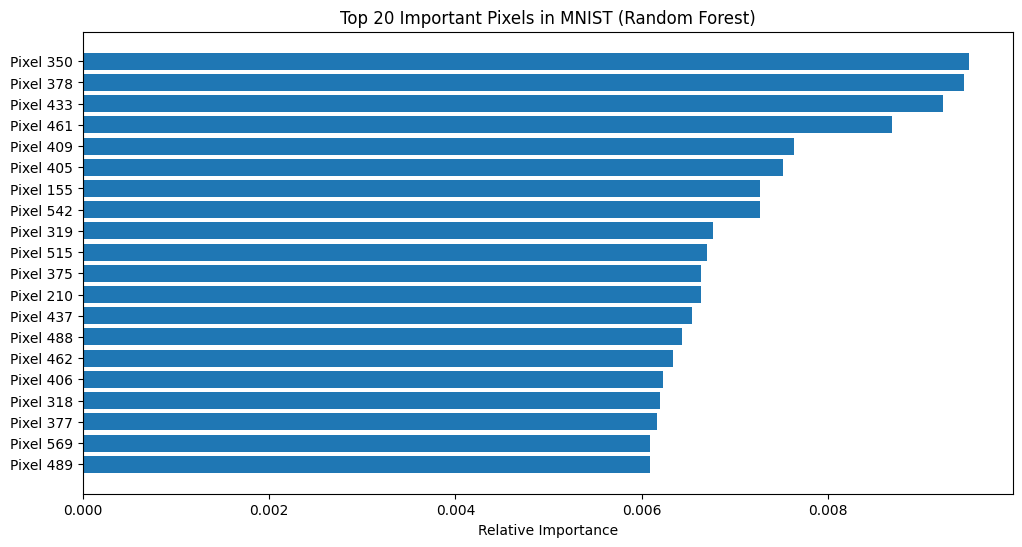

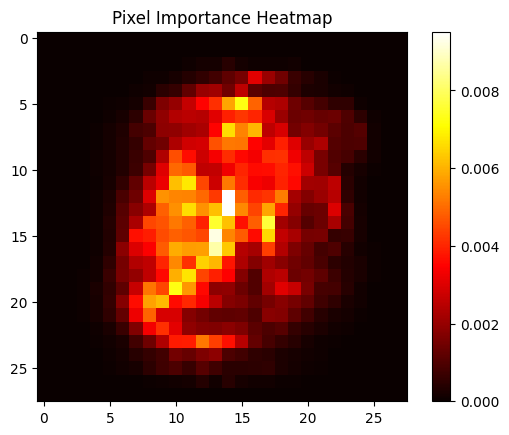

In [9]:
# Get feature importances
importances = rf.feature_importances_
indices = np.argsort(importances)[-20:]  # Top 20 important pixels
# Visualization
plt.figure(figsize=(12,6))
plt.title("Top 20 Important Pixels in MNIST (Random Forest)")
plt.barh(range(20), importances[indices], align='center')
plt.yticks(range(20), [f"Pixel {i}" for i in indices])
plt.xlabel("Relative Importance")
plt.show()
# Visualize important pixels on digit
plt.imshow(importances.reshape(28,28), cmap='hot')
plt.title("Pixel Importance Heatmap")
plt.colorbar()
plt.show()

In [10]:
from sklearn.ensemble import AdaBoostClassifier
ada = AdaBoostClassifier(
    DecisionTreeClassifier(max_depth=1),  # Decision stumps
    n_estimators=200,
    learning_rate=0.5,
    random_state=42
)
ada.fit(X_train, y_train)
# Evaluation
y_pred_ada = ada.predict(X_test)
print(f"AdaBoost Accuracy: {accuracy_score(y_test, y_pred_ada):.4f}")

AdaBoost Accuracy: 0.7788


In [11]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    random_state=42
)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
print(f"Gradient Boosting Accuracy:{ accuracy_score(y_test,y_pred_gb):.4f}")

Gradient Boosting Accuracy:0.9469


In [ ]:
#Stacking multiple Classifiers:
from sklearn.ensemble import StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
# Define base estimators
estimators = [
('random_forest', RandomForestClassifier(n_estimators=50, random_state=42)),
('svm', SVC(kernel='rbf', probability=True, random_state=42)),
('knn', KNeighborsClassifier(n_neighbors=5))
]
# Stack with logistic regression as final estimator
stack = StackingClassifier(
estimators=estimators,
final_estimator=LogisticRegression(max_iter=1000),
cv=5,
stack_method='predict_proba'  # Use probabilities instead of hard predictions
)
stack.fit(X_train, y_train)
y_pred_stack = stack.predict(X_test)
print(f"Stacking Classifier Accuracy: {accuracy_score(y_test, y_pred_stack):.4f}")

In [12]:
#Performance Comparison
# Collect all results
results = {
'Decision Tree': accuracy_score(y_test, dt.predict(X_test)),
'SVM': accuracy_score(y_test, svm.predict(X_test)),
'Random Forest': accuracy_score(y_test, y_pred_rf),
'AdaBoost': accuracy_score(y_test, y_pred_ada),
'Gradient Boosting': accuracy_score(y_test, y_pred_gb),
'Stacking': accuracy_score(y_test, y_pred_stack)
}
# Visual comparison
plt.figure(figsize=(10,6))
plt.barh(list(results.keys()), list(results.values()))
plt.xlim(0.85, 1.0)
plt.title('MNIST Classification Accuracy Comparison')
plt.xlabel('Accuracy')
plt.grid(axis='x', linestyle='--')
plt.show()

NameError: name 'y_pred_stack' is not defined